# MovieLens 1M: Movie Recommendation System
Builds and compares rating-prediction models on MovieLens 1M (1M ratings, 6,040 users, 3,883 movies), then wraps the best one in a simple recommender.

**Step 1: Load data.** Extract the zip and read `ratings`, `movies`, `users` (`::`-separated `.dat` files).

In [2]:
import os
import zipfile
import pandas as pd

# Extract the dataset
zip_path = "ml-1m.zip"
extract_path = "data/ml-1m"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("Dataset extracted successfully.")

# Find the extracted files
for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(os.path.join(root, file))

# Load ratings
ratings = pd.read_csv(
    os.path.join(extract_path, "ratings.dat"),
    sep="::",
    engine="python",
    names=["UserID", "MovieID", "Rating", "Timestamp"],
    encoding="latin-1"
)

# Load movie information
movies = pd.read_csv(
    os.path.join(extract_path, "movies.dat"),
    sep="::",
    engine="python",
    names=["MovieID", "Title", "Genres"],
    encoding="latin-1"
)

# Load user information
users = pd.read_csv(
    os.path.join(extract_path, "users.dat"),
    sep="::",
    engine="python",
    names=["UserID", "Gender", "Age", "Occupation", "Zip-code"],
    encoding="latin-1"
)

print("\nDATASETS LOADED SUCCESSFULLY")
print("=" * 50)

print("Ratings shape:", ratings.shape)
print("Movies shape:", movies.shape)
print("Users shape:", users.shape)

print("\nRATINGS SAMPLE")
display(ratings.head())

print("\nMOVIES SAMPLE")
display(movies.head())

print("\nUSERS SAMPLE")
display(users.head())

Dataset extracted successfully.
/content/movielens_data/movies.dat
/content/movielens_data/users.dat
/content/movielens_data/README
/content/movielens_data/ratings.dat

DATASETS LOADED SUCCESSFULLY
Ratings shape: (1000209, 4)
Movies shape: (3883, 3)
Users shape: (6040, 5)

RATINGS SAMPLE


,UserID,MovieID,Rating,Timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291



MOVIES SAMPLE


,MovieID,Title,Genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy



USERS SAMPLE


,UserID,Gender,Age,Occupation,Zip-code
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117
3,4,M,45,7,02460
4,5,M,25,20,55455


**Step 2: EDA.** Check types, nulls, duplicates and rating distribution, plus most-rated movies and ratings per user. Why: know the data (skew, sparsity) before modelling.

DATASET OVERVIEW
Ratings: (1000209, 4)
Movies: (3883, 3)
Users: (6040, 5)

DATA TYPES

Ratings:
UserID       int64
MovieID      int64
Rating       int64
Timestamp    int64
dtype: object

Movies:
MovieID     int64
Title      object
Genres     object
dtype: object

Users:
UserID         int64
Gender        object
Age            int64
Occupation     int64
Zip-code      object
dtype: object

MISSING VALUES
Ratings:
 UserID       0
MovieID      0
Rating       0
Timestamp    0
dtype: int64
Movies:
 MovieID    0
Title      0
Genres     0
dtype: int64
Users:
 UserID        0
Gender        0
Age           0
Occupation    0
Zip-code      0
dtype: int64

DUPLICATE RECORDS
Ratings: 0
Movies: 0
Users: 0

UNIQUE VALUES
Unique users in ratings: 6040
Unique movies in ratings: 3706
Unique movie IDs in movie table: 3883
Unique user IDs in user table: 6040

RATING DISTRIBUTION
Rating
1     56174
2    107557
3    261197
4    348971
5    226310
Name: count, dtype: int64

RATING PERCENTAGES
Rating
1     5.6

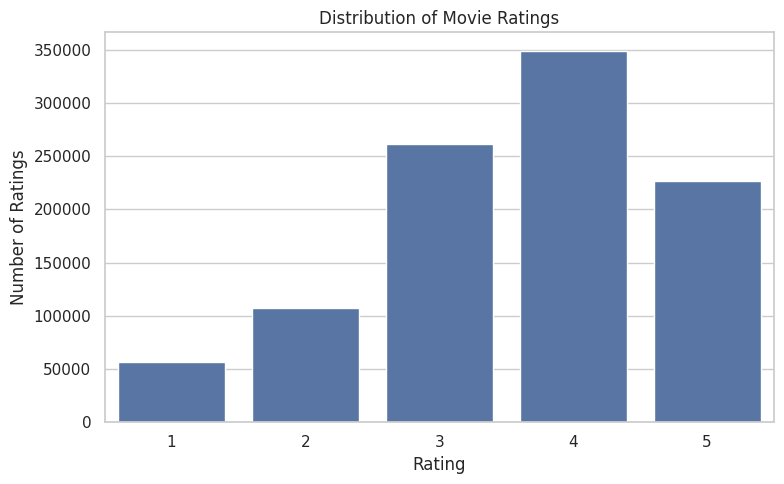

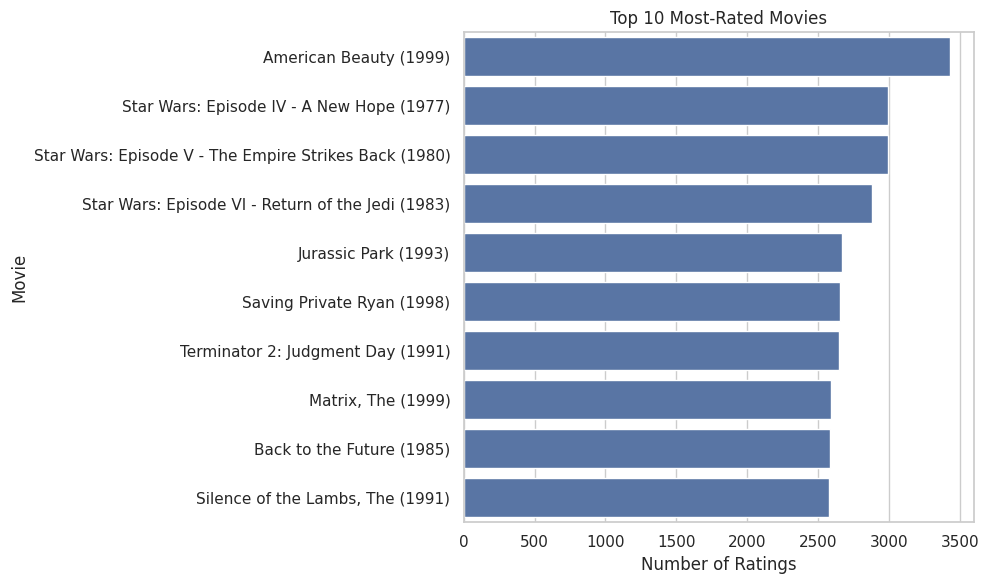

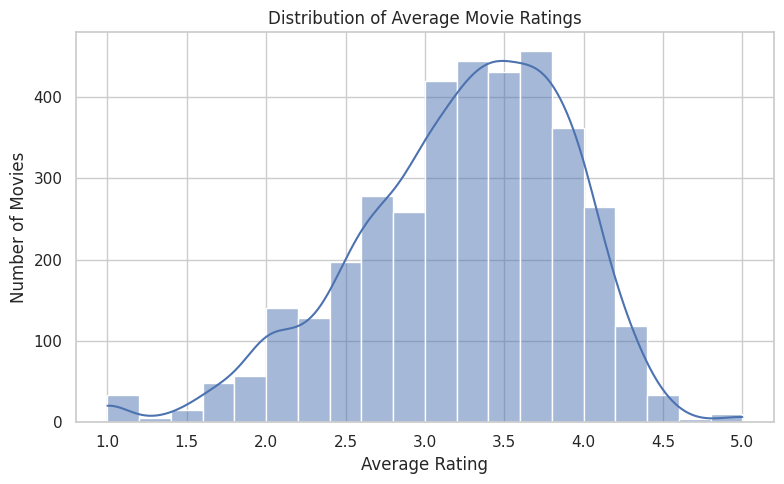

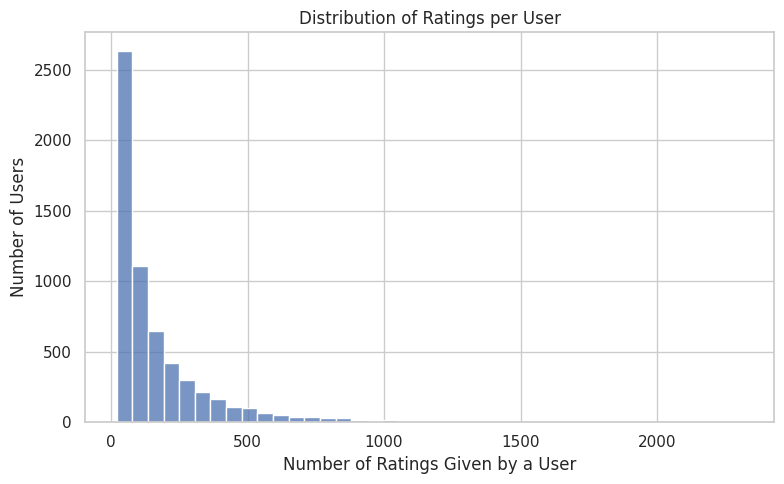

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset overview
print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print("Ratings:", ratings.shape)
print("Movies:", movies.shape)
print("Users:", users.shape)

print("\nDATA TYPES")
print("\nRatings:")
print(ratings.dtypes)
print("\nMovies:")
print(movies.dtypes)
print("\nUsers:")
print(users.dtypes)

# Missing values
print("\nMISSING VALUES")
print("Ratings:\n", ratings.isnull().sum())
print("Movies:\n", movies.isnull().sum())
print("Users:\n", users.isnull().sum())

# Duplicate records
print("\nDUPLICATE RECORDS")
print("Ratings:", ratings.duplicated().sum())
print("Movies:", movies.duplicated().sum())
print("Users:", users.duplicated().sum())

# Unique users and movies
print("\nUNIQUE VALUES")
print("Unique users in ratings:", ratings["UserID"].nunique())
print("Unique movies in ratings:", ratings["MovieID"].nunique())
print("Unique movie IDs in movie table:", movies["MovieID"].nunique())
print("Unique user IDs in user table:", users["UserID"].nunique())

# Rating distribution
print("\nRATING DISTRIBUTION")
print(ratings["Rating"].value_counts().sort_index())

print("\nRATING PERCENTAGES")
print((ratings["Rating"].value_counts(normalize=True).sort_index() * 100).round(2))

# Rating statistics
print("\nRATING STATISTICS")
print(ratings["Rating"].describe())

# Merge ratings with movie titles for analysis
movie_ratings = ratings.merge(
    movies[["MovieID", "Title", "Genres"]],
    on="MovieID",
    how="left"
)

# Average rating and number of ratings per movie
movie_stats = movie_ratings.groupby(
    ["MovieID", "Title"]
).agg(
    Average_Rating=("Rating", "mean"),
    Number_of_Ratings=("Rating", "count")
).reset_index()

print("\nTOP 10 MOST-RATED MOVIES")
print(
    movie_stats.sort_values(
        "Number_of_Ratings", ascending=False
    )[["Title", "Number_of_Ratings", "Average_Rating"]]
    .head(10).to_string(index=False)
)

# Visualizations
sns.set_theme(style="whitegrid")

# 1. Distribution of ratings
plt.figure(figsize=(8, 5))
sns.countplot(data=ratings, x="Rating")
plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.tight_layout()
plt.show()

# 2. Most frequently rated movies
top_movies = movie_stats.nlargest(10, "Number_of_Ratings")

plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_movies,
    x="Number_of_Ratings",
    y="Title"
)
plt.title("Top 10 Most-Rated Movies")
plt.xlabel("Number of Ratings")
plt.ylabel("Movie")
plt.tight_layout()
plt.show()

# 3. Average rating distribution across movies
plt.figure(figsize=(8, 5))
sns.histplot(movie_stats["Average_Rating"], bins=20, kde=True)
plt.title("Distribution of Average Movie Ratings")
plt.xlabel("Average Rating")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

# 4. Ratings per user
ratings_per_user = ratings.groupby("UserID").size()

plt.figure(figsize=(8, 5))
sns.histplot(ratings_per_user, bins=40)
plt.title("Distribution of Ratings per User")
plt.xlabel("Number of Ratings Given by a User")
plt.ylabel("Number of Users")
plt.tight_layout()
plt.show()

**Step 3: Cleaning.** Validate rating range and user/movie IDs, convert timestamps, split genres into lists, build a merged table. Why: confirm the data is safe to model. Nothing needed removing.

In [4]:
# DATA CLEANING AND VALIDATION

import pandas as pd
import numpy as np

# Create working copies
ratings_clean = ratings.copy()
movies_clean = movies.copy()
users_clean = users.copy()

print("BEFORE CLEANING")
print("Ratings:", ratings_clean.shape)
print("Movies:", movies_clean.shape)
print("Users:", users_clean.shape)

# 1. Check for invalid rating values
print("\nINVALID RATINGS")
print(
    "Ratings outside the 1-5 range:",
    (~ratings_clean["Rating"].between(1, 5)).sum()
)

# 2. Check whether rating records reference valid users and movies
invalid_users = ~ratings_clean["UserID"].isin(users_clean["UserID"])
invalid_movies = ~ratings_clean["MovieID"].isin(movies_clean["MovieID"])

print("\nREFERENTIAL INTEGRITY")
print("Ratings with unknown users:", invalid_users.sum())
print("Ratings with unknown movies:", invalid_movies.sum())

# 3. Check missing values and duplicates again
print("\nDATA QUALITY CHECK")
print("Missing rating values:", ratings_clean.isnull().sum().sum())
print("Missing movie values:", movies_clean.isnull().sum().sum())
print("Missing user values:", users_clean.isnull().sum().sum())
print("Duplicate ratings:", ratings_clean.duplicated().sum())
print("Duplicate movie IDs:", movies_clean["MovieID"].duplicated().sum())
print("Duplicate user IDs:", users_clean["UserID"].duplicated().sum())

# 4. Remove invalid records only if any are present
ratings_clean = ratings_clean[
    ratings_clean["Rating"].between(1, 5)
    & ratings_clean["UserID"].isin(users_clean["UserID"])
    & ratings_clean["MovieID"].isin(movies_clean["MovieID"])
].copy()

# 5. Convert timestamps into readable dates
ratings_clean["RatingDate"] = pd.to_datetime(
    ratings_clean["Timestamp"],
    unit="s",
    origin="unix",
    errors="coerce"
)

# 6. Prepare movie genres for feature engineering
movies_clean["Genres"] = movies_clean["Genres"].fillna("")
movies_clean["GenreList"] = movies_clean["Genres"].apply(
    lambda value: value.split("|") if value else []
)

# 7. Create a combined dataset for analysis
movie_ratings_clean = ratings_clean.merge(
    movies_clean[["MovieID", "Title", "Genres", "GenreList"]],
    on="MovieID",
    how="left",
    validate="many_to_one"
)

movie_ratings_clean = movie_ratings_clean.merge(
    users_clean[["UserID", "Gender", "Age", "Occupation"]],
    on="UserID",
    how="left",
    validate="many_to_one"
)

print("\nAFTER CLEANING")
print("Ratings:", ratings_clean.shape)
print("Movies:", movies_clean.shape)
print("Users:", users_clean.shape)
print("Combined dataset:", movie_ratings_clean.shape)
print("Missing movie titles after merge:", movie_ratings_clean["Title"].isnull().sum())
print("Missing user IDs after merge:", movie_ratings_clean["Gender"].isnull().sum())

print("\nCLEANED DATA SAMPLE")
display(movie_ratings_clean.head())

print("\nCLEANING AND VALIDATION COMPLETE")

BEFORE CLEANING
Ratings: (1000209, 4)
Movies: (3883, 3)
Users: (6040, 5)

INVALID RATINGS
Ratings outside the 1-5 range: 0

REFERENTIAL INTEGRITY
Ratings with unknown users: 0
Ratings with unknown movies: 0

DATA QUALITY CHECK
Missing rating values: 0
Missing movie values: 0
Missing user values: 0
Duplicate ratings: 0
Duplicate movie IDs: 0
Duplicate user IDs: 0

AFTER CLEANING
Ratings: (1000209, 5)
Movies: (3883, 4)
Users: (6040, 5)
Combined dataset: (1000209, 11)
Missing movie titles after merge: 0
Missing user IDs after merge: 0

CLEANED DATA SAMPLE


,UserID,MovieID,Rating,Timestamp,RatingDate,Title,Genres,GenreList,Gender,Age,Occupation
0,1,1193,5,978300760,2000-12-31 22:12:40,One Flew Over the Cuckoo's Nest (1975),Drama,[Drama],F,1,10
1,1,661,3,978302109,2000-12-31 22:35:09,James and the Giant Peach (1996),Animation|Children's|Musical,"[Animation, Children's, Musical]",F,1,10
2,1,914,3,978301968,2000-12-31 22:32:48,My Fair Lady (1964),Musical|Romance,"[Musical, Romance]",F,1,10
3,1,3408,4,978300275,2000-12-31 22:04:35,Erin Brockovich (2000),Drama,[Drama],F,1,10
4,1,2355,5,978824291,2001-01-06 23:38:11,"Bug's Life, A (1998)",Animation|Children's|Comedy,"[Animation, Children's, Comedy]",F,1,10



CLEANING AND VALIDATION COMPLETE


**Step 4: Features + split.** Multi-hot encode genres, 80/20 random train/test split, compute the training mean. Why: all stats come from train only, so no leakage into the test set.

In [5]:
# FEATURE ENGINEERING AND TRAIN-TEST SPLIT

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer

# 1. Create useful movie and user statistics
movie_rating_counts = ratings_clean.groupby("MovieID").size()
user_rating_counts = ratings_clean.groupby("UserID").size()

print("FEATURE ENGINEERING")
print("=" * 50)
print("Total ratings:", len(ratings_clean))
print("Unique users:", ratings_clean["UserID"].nunique())
print("Unique rated movies:", ratings_clean["MovieID"].nunique())

print("\nRatings per user:")
print(user_rating_counts.describe().round(2))

print("\nRatings per movie:")
print(movie_rating_counts.describe().round(2))

# 2. Convert movie genres into binary features
genre_encoder = MultiLabelBinarizer()

genre_matrix = genre_encoder.fit_transform(
    movies_clean["GenreList"]
)

genre_features = pd.DataFrame(
    genre_matrix,
    columns=genre_encoder.classes_,
    index=movies_clean["MovieID"]
)

print("\nGENRE FEATURES")
print("Number of genres:", len(genre_encoder.classes_))
print("Genres:", list(genre_encoder.classes_))
print("Genre feature matrix:", genre_features.shape)

# 3. Split ratings into training and testing sets
train_ratings, test_ratings = train_test_split(
    ratings_clean[["UserID", "MovieID", "Rating"]],
    test_size=0.20,
    random_state=42
)

train_ratings = train_ratings.reset_index(drop=True)
test_ratings = test_ratings.reset_index(drop=True)

print("\nTRAIN-TEST SPLIT")
print("Training ratings:", train_ratings.shape)
print("Testing ratings:", test_ratings.shape)
print("Training percentage:", round(len(train_ratings) / len(ratings_clean) * 100, 2))
print("Testing percentage:", round(len(test_ratings) / len(ratings_clean) * 100, 2))

# 4. Calculate a training-only rating baseline
global_mean_rating = train_ratings["Rating"].mean()

print("\nTRAINING BASELINE")
print("Mean training rating:", round(global_mean_rating, 4))

print("\nFEATURE ENGINEERING AND SPLITTING COMPLETE")

FEATURE ENGINEERING
Total ratings: 1000209
Unique users: 6040
Unique rated movies: 3706

Ratings per user:
count    6040.00
mean      165.60
std       192.75
min        20.00
25%        44.00
50%        96.00
75%       208.00
max      2314.00
dtype: float64

Ratings per movie:
count    3706.00
mean      269.89
std       384.05
min         1.00
25%        33.00
50%       123.50
75%       350.00
max      3428.00
dtype: float64

GENRE FEATURES
Number of genres: 18
Genres: ['Action', 'Adventure', 'Animation', "Children's", 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']
Genre feature matrix: (3883, 18)

TRAIN-TEST SPLIT
Training ratings: (800167, 3)
Testing ratings: (200042, 3)
Training percentage: 80.0
Testing percentage: 20.0

TRAINING BASELINE
Mean training rating: 3.5813

FEATURE ENGINEERING AND SPLITTING COMPLETE


**Step 5: Model comparison.** Four models on the same 10k test sample: global mean, shrunk movie average, user+item bias, item-based CF (cosine, k=20). Why: start from simple baselines and see what actually helps.

In [6]:
# TRAIN AND COMPARE RECOMMENDATION MODELS

import numpy as np
import pandas as pd
import time

from scipy.sparse import csr_matrix
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics.pairwise import cosine_similarity

print("TRAINING RECOMMENDATION MODELS")
print("=" * 60)

# Use the same held-out test sample to compare every model fairly.
evaluation_test = test_ratings.sample(
    n=min(10000, len(test_ratings)),
    random_state=42
).reset_index(drop=True)

y_true = evaluation_test["Rating"].to_numpy()

# Model 1: Global average baseline
start = time.time()

global_mean = train_ratings["Rating"].mean()
pred_global = np.full(len(evaluation_test), global_mean)

print(f"\nGlobal mean baseline trained in {time.time() - start:.2f}s")

# Model 2: Popularity-based rating prediction
# Use training ratings only to calculate movie averages.
start = time.time()

movie_means = train_ratings.groupby("MovieID")["Rating"].mean()
movie_counts = train_ratings.groupby("MovieID")["Rating"].count()

# Shrink averages toward the global mean for movies with few ratings.
shrinkage = 10
movie_scores = (
    movie_counts * movie_means + shrinkage * global_mean
) / (movie_counts + shrinkage)

pred_popularity = (
    evaluation_test["MovieID"]
    .map(movie_scores)
    .fillna(global_mean)
    .to_numpy()
)

print(f"Popularity model prepared in {time.time() - start:.2f}s")

# Model 3: User-item bias baseline
# Learn user and movie rating tendencies from training data only.
start = time.time()

regularization = 10
user_bias = pd.Series(0.0, index=users["UserID"])
item_bias = pd.Series(0.0, index=movies["MovieID"])

user_group = train_ratings.groupby("UserID")["Rating"]
item_group = train_ratings.groupby("MovieID")["Rating"]

# Alternating updates for user and movie biases
for _ in range(10):
    user_residual = (
        train_ratings["Rating"]
        - global_mean
        - train_ratings["MovieID"].map(item_bias).fillna(0)
    )
    user_sums = user_residual.groupby(train_ratings["UserID"]).sum()
    user_counts = user_group.count()
    user_bias.update(
        user_sums / (user_counts + regularization)
    )

    item_residual = (
        train_ratings["Rating"]
        - global_mean
        - train_ratings["UserID"].map(user_bias).fillna(0)
    )
    item_sums = item_residual.groupby(train_ratings["MovieID"]).sum()
    item_counts = item_group.count()
    item_bias.update(
        item_sums / (item_counts + regularization)
    )

pred_bias = (
    global_mean
    + evaluation_test["UserID"].map(user_bias).fillna(0).to_numpy()
    + evaluation_test["MovieID"].map(item_bias).fillna(0).to_numpy()
)
pred_bias = np.clip(pred_bias, 1, 5)

print(f"User-item bias model trained in {time.time() - start:.2f}s")

# Model 4: Item-based collaborative filtering
start = time.time()

user_ids = users["UserID"].to_numpy()
movie_ids = movies["MovieID"].to_numpy()

user_to_idx = {uid: i for i, uid in enumerate(user_ids)}
movie_to_idx = {mid: i for i, mid in enumerate(movie_ids)}

train_user_idx = train_ratings["UserID"].map(user_to_idx).to_numpy()
train_movie_idx = train_ratings["MovieID"].map(movie_to_idx).to_numpy()

user_item_matrix = csr_matrix(
    (
        train_ratings["Rating"].to_numpy(dtype=np.float32),
        (train_user_idx, train_movie_idx)
    ),
    shape=(len(user_ids), len(movie_ids)),
    dtype=np.float32
)

# Movie-to-movie cosine similarity, calculated from training data only
item_similarity = cosine_similarity(
    user_item_matrix.T,
    dense_output=True
).astype(np.float32)

# Predict ratings using the 20 most similar movies each user rated.
k_neighbors = 20
pred_cf = []

for row in evaluation_test.itertuples(index=False):
    u_idx = user_to_idx[row.UserID]
    target_idx = movie_to_idx[row.MovieID]

    rated_indices = user_item_matrix[u_idx].indices
    rated_values = user_item_matrix[u_idx].data

    # Exclude the target movie from its own neighbors
    valid = rated_indices != target_idx
    rated_indices = rated_indices[valid]
    rated_values = rated_values[valid]

    if len(rated_indices) == 0:
        pred_cf.append(global_mean)
        continue

    similarities = item_similarity[target_idx, rated_indices]

    positive = similarities > 0
    similarities = similarities[positive]
    neighbor_ratings = rated_values[positive]

    if len(similarities) == 0:
        pred_cf.append(global_mean)
        continue

    top = np.argsort(similarities)[-k_neighbors:]
    top_similarities = similarities[top]
    top_ratings = neighbor_ratings[top]

    prediction = np.average(
        top_ratings,
        weights=top_similarities
    )
    pred_cf.append(np.clip(prediction, 1, 5))

pred_cf = np.array(pred_cf)

print(f"Item-based collaborative filtering trained in {time.time() - start:.2f}s")

# Compare all models on the same test sample
predictions = {
    "Global Mean Baseline": pred_global,
    "Popularity-Based": pred_popularity,
    "User-Item Bias": pred_bias,
    "Item-Based Collaborative Filtering": pred_cf
}

results = []

for model_name, pred in predictions.items():
    results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_true, pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, pred))
    })

results_df = pd.DataFrame(results).sort_values("RMSE")

print("\nMODEL COMPARISON")
print("=" * 60)
display(results_df.round(4))

print("Evaluation sample:", len(evaluation_test))
print("Full test set:", len(test_ratings))

print("\nMODEL TRAINING AND COMPARISON COMPLETE")

TRAINING RECOMMENDATION MODELS

Global mean baseline trained in 0.00s
Popularity model prepared in 0.02s
User-item bias model trained in 0.61s
Item-based collaborative filtering trained in 9.08s

MODEL COMPARISON


,Model,MAE,RMSE
2,User-Item Bias,0.7218,0.9108
3,Item-Based Collaborative Filtering,0.7212,0.9320
1,Popularity-Based,0.7887,0.9851
0,Global Mean Baseline,0.9358,1.1225


Evaluation sample: 10000
Full test set: 200042

MODEL TRAINING AND COMPARISON COMPLETE


**Step 6: Recommender.** Predict ratings for unseen movies with the bias model and return the top N. New users get the most popular movies (cold start).

In [7]:
# MOVIE RECOMMENDATION PROTOTYPE

def recommend_movies(user_id, n=10):
    """
    Recommend movies for an existing user using the trained
    user-item bias model. Unknown users receive popular movies.
    """

    n = max(1, int(n))

    # Handle a user not present in the dataset
    if user_id not in user_to_idx:
        print(f"User {user_id} was not found.")
        print("Showing popular movies for a new user instead.")

        popular = (
            movie_stats.merge(
                movies_clean[["MovieID", "Genres"]],
                on="MovieID",
                how="left"
            )
            .sort_values(
                ["Number_of_Ratings", "Average_Rating"],
                ascending=False
            )
            .head(n)
            .copy()
        )

        display(popular[[
            "Title", "Genres", "Average_Rating", "Number_of_Ratings"
        ]].reset_index(drop=True))
        return popular

    # Movies already rated by this user
    watched = set(
        train_ratings.loc[
            train_ratings["UserID"] == user_id, "MovieID"
        ]
    )

    # Only recommend movies not already rated
    candidates = movies_clean[
        ~movies_clean["MovieID"].isin(watched)
    ].copy()

    # Predict ratings with the trained user-item bias model
    user_effect = user_bias.get(user_id, 0.0)

    candidates["Predicted_Rating"] = (
        global_mean
        + user_effect
        + candidates["MovieID"].map(item_bias).fillna(0)
    ).clip(1, 5)

    # Add movie popularity and genres for context
    candidates["Number_of_Ratings"] = (
        candidates["MovieID"].map(movie_counts).fillna(0).astype(int)
    )

    candidates = candidates.sort_values(
        ["Predicted_Rating", "Number_of_Ratings"],
        ascending=False
    )

    recommendations = candidates.head(n)[[
        "MovieID", "Title", "Genres",
        "Predicted_Rating", "Number_of_Ratings"
    ]].reset_index(drop=True)

    print(f"Top {len(recommendations)} recommendations for User {user_id}")
    display(recommendations.round({"Predicted_Rating": 2}))

    return recommendations


# Try the prototype with User 1
recommendations = recommend_movies(user_id=1, n=10)

Top 10 recommendations for User 1


,MovieID,Title,Genres,Predicted_Rating,Number_of_Ratings
0,2019,Seven Samurai (The Magnificent Seven) (Shichin...,Action|Drama,4.78,497
1,318,"Shawshank Redemption, The (1994)",Drama,4.75,1786
2,50,"Usual Suspects, The (1995)",Crime|Thriller,4.73,1422
3,858,"Godfather, The (1972)",Action|Crime|Drama,4.72,1764
4,1148,"Wrong Trousers, The (1993)",Animation|Comedy,4.72,706
5,922,Sunset Blvd. (a.k.a. Sunset Boulevard) (1950),Film-Noir,4.71,383
6,2905,Sanjuro (1962),Action|Adventure,4.70,58
7,1212,"Third Man, The (1949)",Mystery|Thriller,4.69,387
8,904,Rear Window (1954),Mystery|Thriller,4.68,847
9,750,Dr. Strangelove or: How I Learned to Stop Worr...,Sci-Fi|War,4.67,1086


**Step 7: Final evaluation + save.** User-item bias model won on RMSE (best MAE was a near tie with item CF, and it is far cheaper), so it is tested on the full 200k test set and saved with joblib.

In [9]:
# FINAL MODEL EVALUATION ON THE FULL TEST SET

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

y_true = test_ratings["Rating"].to_numpy()

y_pred = (
    global_mean
    + test_ratings["UserID"].map(user_bias).fillna(0).to_numpy()
    + test_ratings["MovieID"].map(item_bias).fillna(0).to_numpy()
)

y_pred = np.clip(y_pred, 1, 5)

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))

print("=" * 50)
print("FINAL TEST RESULTS")
print("=" * 50)
print(f"Test samples: {len(y_true)}")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

# SAVE MODEL AND PREPROCESSING COMPONENTS

import os
import joblib

save_dir = "../models"
os.makedirs(save_dir, exist_ok=True)

artifacts = {
    "global_mean": global_mean,
    "user_bias": user_bias,
    "item_bias": item_bias,
    "movie_counts": movie_counts,
    "movies": movies_clean,
    "user_to_idx": user_to_idx,
    "genre_encoder": genre_encoder,
    "mae": mae,
    "rmse": rmse
}

model_path = os.path.join(save_dir, "recommendation_model.joblib")
joblib.dump(artifacts, model_path)

print("\nMODEL SAVED")
print(model_path)
print(f"File size: {os.path.getsize(model_path) / (1024**2):.2f} MB")


FINAL TEST RESULTS
Test samples: 200042
MAE:  0.7223
RMSE: 0.9120

MODEL SAVED
/content/movielens_recommendation_project/recommendation_model.joblib
File size: 0.75 MB

Project artifacts packaged.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>